In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
##Problem 1: Comparative Edge Detection on Natural Images
##Download any outdoor natural image (trees, buildings, roads).Apply Sobel, Laplacian, and Canny edge detection.Compare the outputs and write a short analysis explaining which operator captures the most meaningful edges and why.


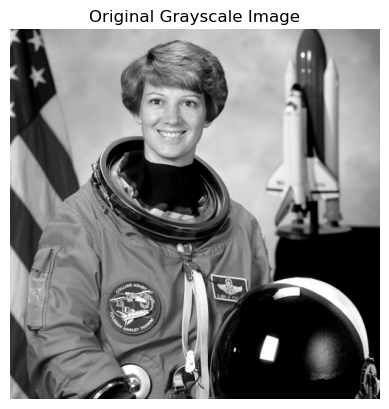

In [2]:
from skimage import data

image = data.astronaut()
image = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)

plt.imshow(image, cmap='gray')
plt.title("Original Grayscale Image")
plt.axis('off')
plt.show()

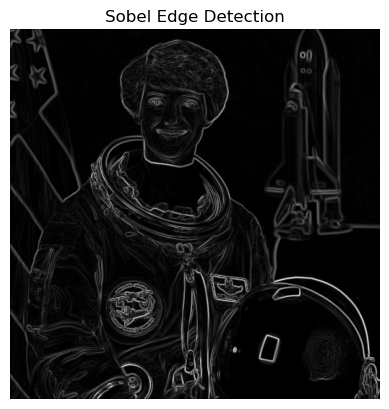

In [3]:
sobel_x = cv2.Sobel(image, cv2.CV_64F, 1, 0, ksize=3)
sobel_y = cv2.Sobel(image, cv2.CV_64F, 0, 1, ksize=3)

sobel = cv2.magnitude(sobel_x, sobel_y)

plt.imshow(sobel, cmap='gray')
plt.title("Sobel Edge Detection")
plt.axis('off')
plt.show()

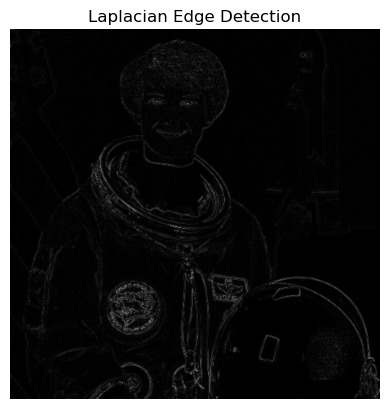

In [4]:
laplacian = cv2.Laplacian(image, cv2.CV_64F)

plt.imshow(np.abs(laplacian), cmap='gray')
plt.title("Laplacian Edge Detection")
plt.axis('off')
plt.show()

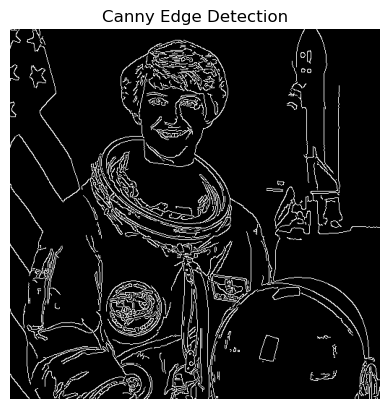

In [5]:
canny = cv2.Canny(image, 100, 200)

plt.imshow(canny, cmap='gray')
plt.title("Canny Edge Detection")
plt.axis('off')
plt.show()

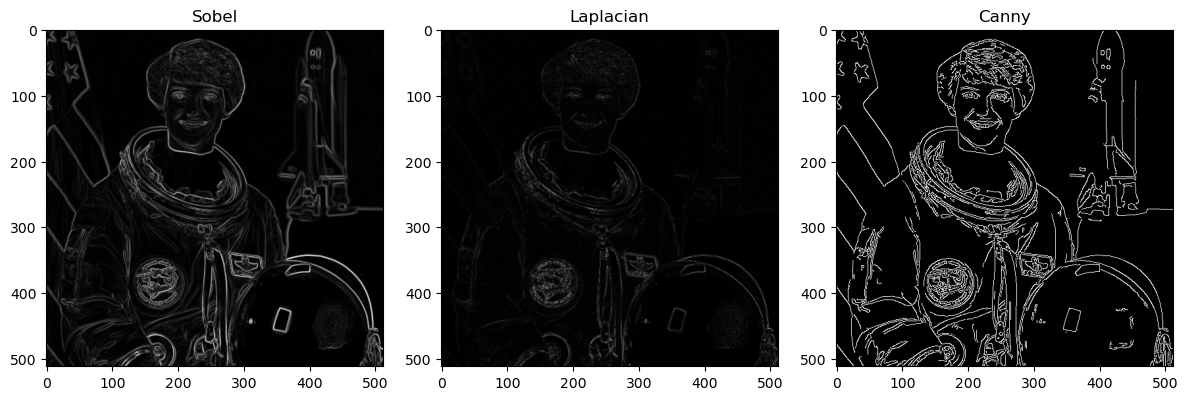

In [6]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(sobel, cmap='gray')
plt.title("Sobel")

plt.subplot(1, 3, 2)
plt.imshow(np.abs(laplacian), cmap='gray')
plt.title("Laplacian")

plt.subplot(1, 3, 3)
plt.imshow(canny, cmap='gray')
plt.title("Canny")

plt.tight_layout()
plt.show()

In [ ]:
##Observation:
##1. Sobel: Detects edges in horizontal and vertical directions. It highlights object boundaries but may produce thicker edges.
##2. Laplacian: Detects edges in all directions but is sensitive to noise and may produce unwanted edges.
##3. Canny: Produces thin, clear and well-defined edges by using smoothing and edge tracking.
##Conclusion:
##Canny edge detection gives the most meaningful results because it detects clear and accurate edges while reducing unwanted noise. Sobel is useful for detecting directional edges, whereas Laplacian detects rapid intensity changes in all directions.

In [ ]:
##Problem 2: Noise Sensitivity Experiment
##Take a clean grayscale image and intentionally add Gaussian noise and salt-and-pepper noise.Apply Sobel and Laplacian on both noisy versions and evaluate:
##Which operator is more affected by noise?
##How does edge clarity change?
##What preprocessing step improves the results?


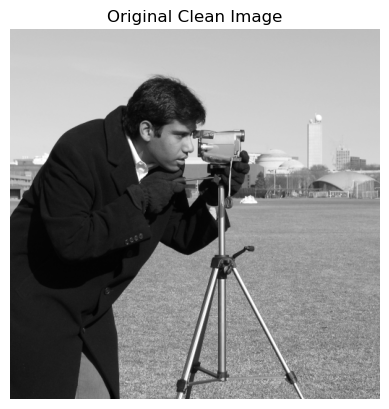

In [7]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage import data

image = data.camera()
image = np.array(image, dtype=np.uint8)

plt.imshow(image, cmap='gray')
plt.title("Original Clean Image")
plt.axis('off')
plt.show()

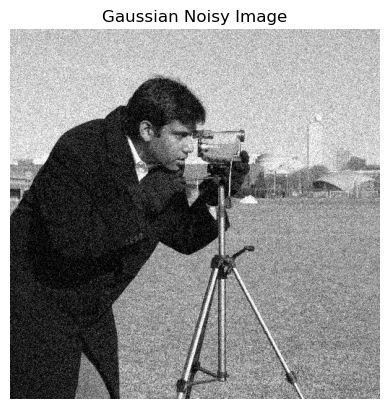

In [8]:
gaussian_noise = np.random.normal(0, 25, image.shape)
gaussian_noisy = np.clip(image + gaussian_noise, 0, 255).astype(np.uint8)

plt.imshow(gaussian_noisy, cmap='gray')
plt.title("Gaussian Noisy Image")
plt.axis('off')
plt.show()

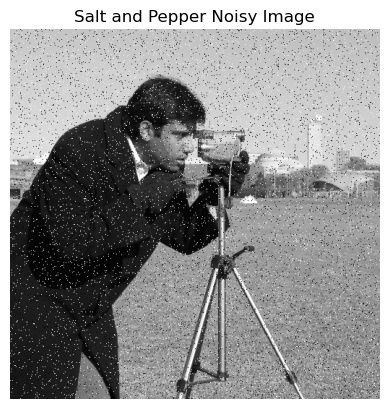

In [9]:
sp_noisy = image.copy()

prob = 0.05
random_values = np.random.random(image.shape)

sp_noisy[random_values < prob/2] = 0
sp_noisy[random_values > 1-prob/2] = 255

plt.imshow(sp_noisy, cmap='gray')
plt.title("Salt and Pepper Noisy Image")
plt.axis('off')
plt.show()

In [12]:
def apply_edges(img):
    sobel_x = cv2.Sobel(img, cv2.CV_64F, 1, 0, ksize=3)
    sobel_y = cv2.Sobel(img, cv2.CV_64F, 0, 1, ksize=3)
    sobel = cv2.magnitude(sobel_x, sobel_y)

    laplacian = cv2.Laplacian(img, cv2.CV_64F)

    return sobel, np.abs(laplacian)

sobel_gaussian, lap_gaussian = apply_edges(gaussian_noisy)
sobel_sp, lap_sp = apply_edges(sp_noisy)

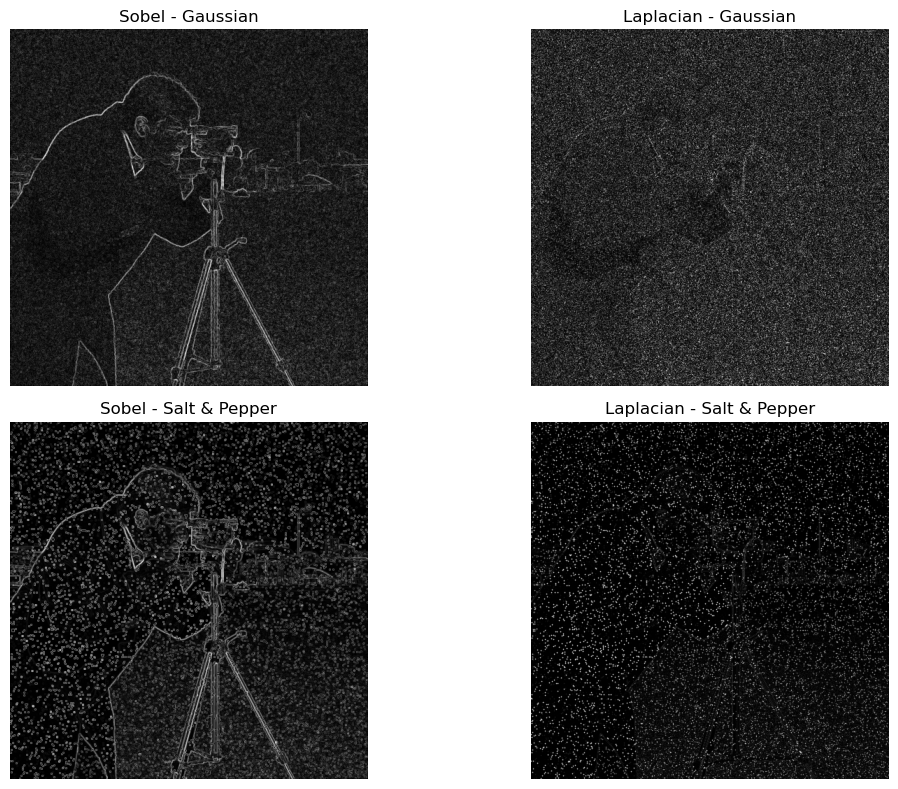

In [11]:
plt.figure(figsize=(12, 8))

images = [
    (sobel_gaussian, "Sobel - Gaussian"),
    (lap_gaussian, "Laplacian - Gaussian"),
    (sobel_sp, "Sobel - Salt & Pepper"),
    (lap_sp, "Laplacian - Salt & Pepper")
]

for i, (img, title) in enumerate(images):
    plt.subplot(2, 2, i+1)
    plt.imshow(img, cmap='gray')
    plt.title(title)
    plt.axis('off')

plt.tight_layout()
plt.show()

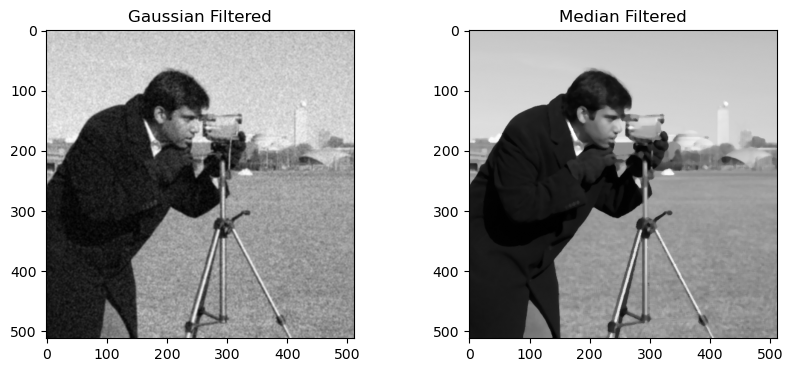

In [13]:
blurred = cv2.GaussianBlur(gaussian_noisy, (5, 5), 0)
filtered = cv2.medianBlur(sp_noisy, 5)

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(blurred, cmap='gray')
plt.title("Gaussian Filtered")

plt.subplot(1, 2, 2)
plt.imshow(filtered, cmap='gray')
plt.title("Median Filtered")

plt.show()

In [ ]:
##Observation
##- Sobel detects edges but becomes noisy when noise is added.
##- Laplacian is more sensitive to noise because it uses second-order derivatives.
##- Gaussian noise reduces edge clarity.
##- Salt-and-pepper noise creates unwanted bright and dark spots.
##- Gaussian blur helps reduce Gaussian noise.
##- Median filtering effectively removes salt-and-pepper noise.
##Conclusion: Laplacian is more affected by noise than Sobel. Applying suitable preprocessing filters improves edge detection and produces clearer results.

In [ ]:
##Problem 3: Compression Ratio Comparison (RLE vs Huffman)
##Load a grayscale image with large smooth regions (e.g., document scan or sky image).Compress it using Run-Length Encoding and Huffman Coding separately.Calculate and compare:
##Bit-length before compression
##Bit-length after compression
##Percentage reductionExplain why each technique performed the way it did.


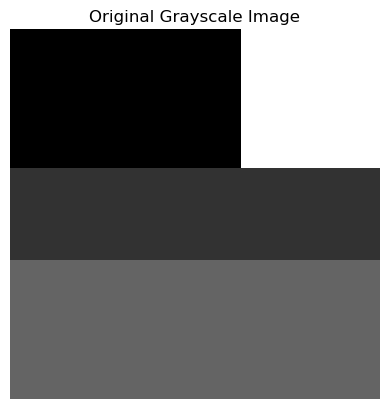

In [14]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import heapq
from collections import Counter

image = np.array([
    [0,0,0,0,0,255,255,255],
    [0,0,0,0,0,255,255,255],
    [0,0,0,0,0,255,255,255],
    [50,50,50,50,50,50,50,50],
    [50,50,50,50,50,50,50,50],
    [100,100,100,100,100,100,100,100],
    [100,100,100,100,100,100,100,100],
    [100,100,100,100,100,100,100,100]
], dtype=np.uint8)

plt.imshow(image, cmap='gray')
plt.title("Original Grayscale Image")
plt.axis('off')
plt.show()

In [15]:
original_bits = image.size * 8
print("Original Bit Length:", original_bits)

Original Bit Length: 512


In [16]:
def rle_encode(data):
    encoded = []
    count = 1

    for i in range(1, len(data)):
        if data[i] == data[i-1]:
            count += 1
        else:
            encoded.append((data[i-1], count))
            count = 1

    encoded.append((data[-1], count))
    return encoded

flat_image = image.flatten()
rle_data = rle_encode(flat_image)

rle_bits = len(rle_data) * 16

print("RLE Encoded Data:", rle_data)
print("RLE Bit Length:", rle_bits)

RLE Encoded Data: [(np.uint8(0), 5), (np.uint8(255), 3), (np.uint8(0), 5), (np.uint8(255), 3), (np.uint8(0), 5), (np.uint8(255), 3), (np.uint8(50), 16), (np.uint8(100), 24)]
RLE Bit Length: 128


In [17]:
def huffman_encode(data):
    frequency = Counter(data)

    heap = [[freq, [symbol, ""]] for symbol, freq in frequency.items()]
    heapq.heapify(heap)

    if len(heap) == 1:
        return {heap[0][1][0]: "0"}

    while len(heap) > 1:
        left = heapq.heappop(heap)
        right = heapq.heappop(heap)

        for pair in left[1:]:
            pair[1] = '0' + pair[1]

        for pair in right[1:]:
            pair[1] = '1' + pair[1]

        heapq.heappush(heap, [left[0] + right[0]] + left[1:] + right[1:])

    return {symbol: code for symbol, code in heap[0][1:]}

codes = huffman_encode(flat_image)
huffman_bits = sum(Counter(flat_image)[pixel] * len(codes[pixel]) for pixel in codes)

print("Huffman Codes:", codes)
print("Huffman Bit Length:", huffman_bits)

Huffman Codes: {np.uint8(255): '00', np.uint8(0): '01', np.uint8(50): '10', np.uint8(100): '11'}
Huffman Bit Length: 128


In [18]:
rle_reduction = ((original_bits - rle_bits) / original_bits) * 100
huffman_reduction = ((original_bits - huffman_bits) / original_bits) * 100

print("Original Bits:", original_bits)
print("RLE Bits:", rle_bits)
print("Huffman Bits:", huffman_bits)

print("RLE Reduction:", round(rle_reduction, 2), "%")
print("Huffman Reduction:", round(huffman_reduction, 2), "%")

Original Bits: 512
RLE Bits: 128
Huffman Bits: 128
RLE Reduction: 75.0 %
Huffman Reduction: 75.0 %


In [ ]:
##Observation
##- RLE works well when an image contains large continuous regions of the same pixel values.
##- Huffman coding assigns shorter codes to frequently occurring pixel values.
##- RLE performance depends on repeated consecutive pixels.
##- Huffman coding depends on the frequency distribution of pixel values.
##Conclusion: Both techniques reduce image storage requirements. RLE is effective for images with large uniform regions, while Huffman coding is effective when some pixel values occur more frequently than others.

In [ ]:
##Problem 4: JPEG Block Artifact Analysis
##Implement an 8×8 block-based JPEG-style compression (DCT + quantisation).Compress the same image using low, medium, and high quantisation levels.Analyse:
##Where block artifacts appear
##Why some textures lose detail
##How PSNR and SSIM change at each level



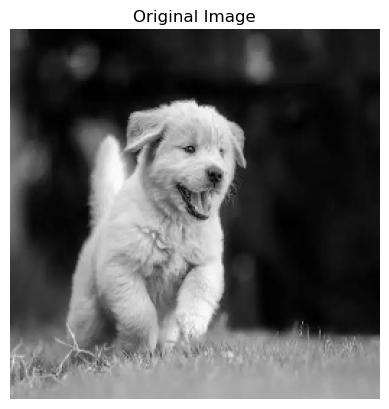

In [27]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage.metrics import peak_signal_noise_ratio, structural_similarity

image = cv2.imread('image.jpg', cv2.IMREAD_GRAYSCALE)

image = cv2.resize(image, (256, 256))

plt.imshow(image, cmap='gray')
plt.title("Original Image")
plt.axis('off')
plt.show()

In [20]:
from skimage import data
image = cv2.resize(data.camera(), (256, 256))

In [28]:
def jpeg_compression(image, q):
    result = np.zeros_like(image, dtype=np.float32)

    for i in range(0, image.shape[0], 8):
        for j in range(0, image.shape[1], 8):

            block = image[i:i+8, j:j+8].astype(np.float32)

            dct = cv2.dct(block - 128)

            quantized = np.round(dct / q) * q

            reconstructed = cv2.idct(quantized) + 128

            result[i:i+8, j:j+8] = reconstructed

    return np.clip(result, 0, 255).astype(np.uint8)

In [31]:
low = jpeg_compression(image, 5)
medium = jpeg_compression(image, 20)
high = jpeg_compression(image, 50)

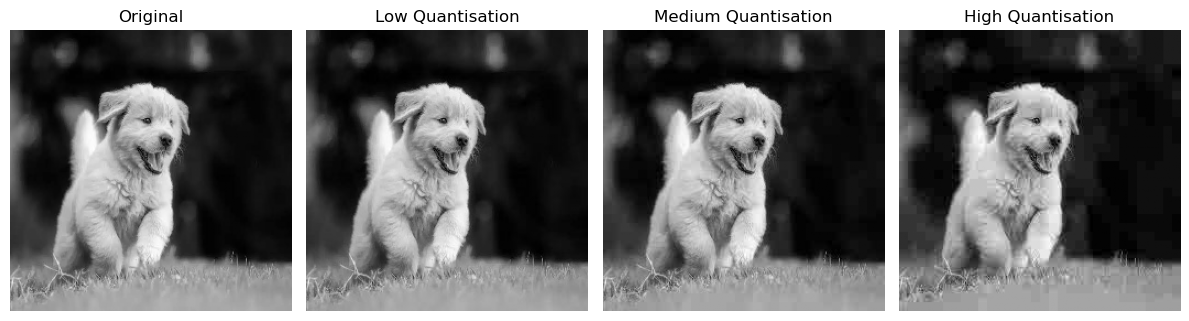

In [30]:
plt.figure(figsize=(12, 4))

images = [image, low, medium, high]
titles = ["Original", "Low Quantisation", "Medium Quantisation", "High Quantisation"]

for i in range(4):
    plt.subplot(1, 4, i+1)
    plt.imshow(images[i], cmap='gray')
    plt.title(titles[i])
    plt.axis('off')

plt.tight_layout()
plt.show()

In [24]:
results = [low, medium, high]
levels = ["Low", "Medium", "High"]

for level, compressed in zip(levels, results):
    psnr = peak_signal_noise_ratio(image, compressed, data_range=255)
    ssim = structural_similarity(image, compressed, data_range=255)

    print(level, "Quantisation")
    print("PSNR:", round(psnr, 2), "dB")
    print("SSIM:", round(ssim, 4))
    print()

Low Quantisation
PSNR: 45.65 dB
SSIM: 0.9911

Medium Quantisation
PSNR: 35.92 dB
SSIM: 0.9396

High Quantisation
PSNR: 30.62 dB
SSIM: 0.83



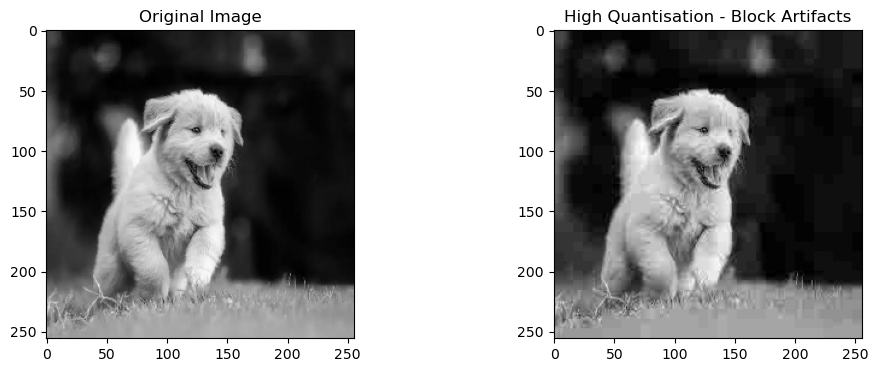

In [32]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.imshow(image, cmap='gray')
plt.title("Original Image")

plt.subplot(1, 2, 2)
plt.imshow(high, cmap='gray')
plt.title("High Quantisation - Block Artifacts")

plt.show()

In [ ]:
##Observation
##1. Low quantisation preserves most image details and produces better quality.
##2. Medium quantisation reduces file information while maintaining reasonable image quality.
##3. High quantisation removes more high-frequency information, causing visible block artifacts and loss of texture.
##4. PSNR and SSIM generally decrease as quantisation becomes stronger.
##Conclusion:

##JPEG compression uses DCT and quantisation to reduce image data. Low quantisation provides better image quality, whereas high quantisation achieves greater compression but introduces visible distortion.

In [ ]:
##Problem 5: Texture-Based Segmentation using GLCM Features
##Load a synthetic or natural image that contains multiple textures (wood, fabric, leaves, tiles).Extract GLCM features (contrast, energy, homogeneity) for each pixel neighbourhood.Segment the image into k = 3 clusters using these features.Write observations on how feature choice influences segmentation quality.


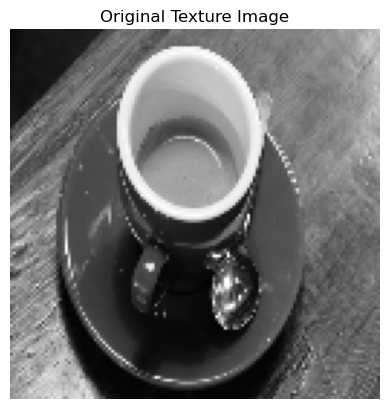

In [33]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

from skimage import data
from skimage.feature import graycomatrix, graycoprops
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

image = data.coffee()
image = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)
image = cv2.resize(image, (128, 128))

plt.imshow(image, cmap='gray')
plt.title("Original Texture Image")
plt.axis('off')
plt.show()

In [34]:
def extract_glcm_features(image, window=9):
    quantized = (image // 32).astype(np.uint8)
    features = []

    pad = window // 2
    padded = np.pad(quantized, pad, mode='reflect')

    for i in range(image.shape[0]):
        for j in range(image.shape[1]):
            patch = padded[i:i+window, j:j+window]

            glcm = graycomatrix(
                patch,
                distances=[1],
                angles=[0],
                levels=8,
                symmetric=True,
                normed=True
            )

            contrast = graycoprops(glcm, 'contrast')[0, 0]
            energy = graycoprops(glcm, 'energy')[0, 0]
            homogeneity = graycoprops(glcm, 'homogeneity')[0, 0]

            features.append([contrast, energy, homogeneity])

    return np.array(features)

features = extract_glcm_features(image)

print("GLCM Features Shape:", features.shape)
print("First 5 Features:\n", features[:5])

GLCM Features Shape: (16384, 3)
First 5 Features:
 [[0. 1. 1.]
 [0. 1. 1.]
 [0. 1. 1.]
 [0. 1. 1.]
 [0. 1. 1.]]


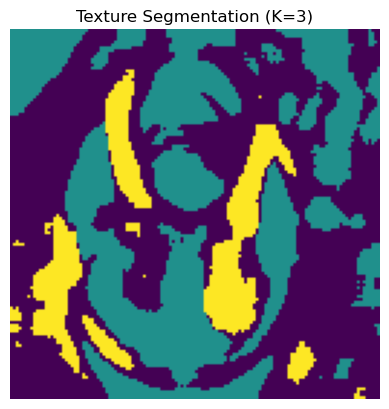

In [35]:
scaler = StandardScaler()
scaled_features = scaler.fit_transform(features)

kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)

labels = kmeans.fit_predict(scaled_features)

segmented = labels.reshape(image.shape)

plt.imshow(segmented, cmap='viridis')
plt.title("Texture Segmentation (K=3)")
plt.axis('off')
plt.show()

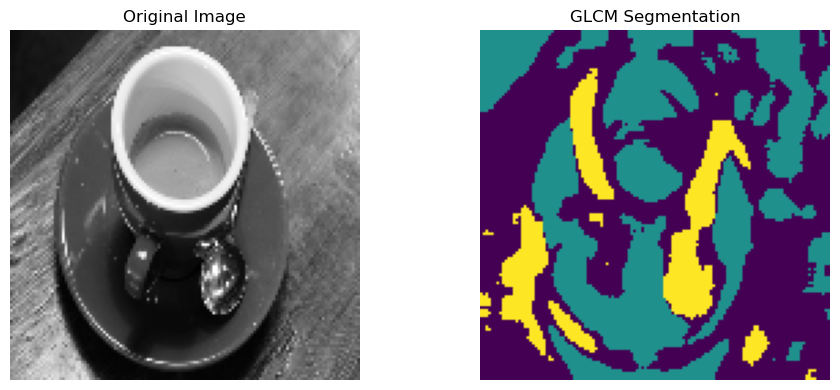

In [36]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(image, cmap='gray')
plt.title("Original Image")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(segmented, cmap='viridis')
plt.title("GLCM Segmentation")
plt.axis('off')

plt.tight_layout()
plt.show()

In [ ]:
##Step 5 – Observation
##Observation:
##1. Contrast identifies differences in neighbouring pixel intensities.
##2. Energy measures texture uniformity.
##3. Homogeneity identifies smooth and similar pixel regions.
##4. K-Means divides the image into three texture-based clusters.
##5. Combining all three features improves segmentation compared to using only one feature.
##Conclusion:

##GLCM features help identify different textures in an image. K-Means clustering groups similar texture regions into three clusters. Combining contrast, energy and homogeneity provides better segmentation results.

In [ ]:
##Problem 6: Multi-Feature Segmentation for Disease Detection
##Load a plant or skin lesion image.Construct a feature vector combining:
##Intensity
##Gradient magnitude (Sobel)
##Local texture varianceSegment the image using K-means or Mean Shift.Evaluate:
##Which feature contributed most to separating diseased vs healthy regions
##Any misclassifications and why they occurred


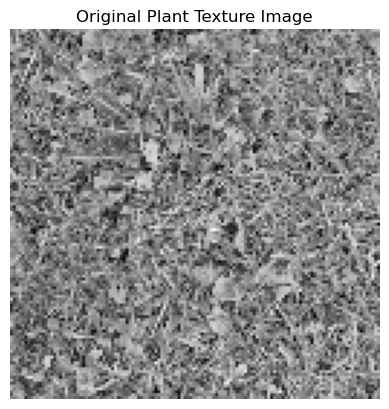

In [37]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

from skimage import data
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

image = data.grass()
image = cv2.resize(image, (128, 128))

plt.imshow(image, cmap='gray')
plt.title("Original Plant Texture Image")
plt.axis('off')
plt.show()

In [38]:
# 1. Intensity
intensity = image.astype(np.float32)

# 2. Gradient Magnitude using Sobel
sobel_x = cv2.Sobel(intensity, cv2.CV_32F, 1, 0, ksize=3)
sobel_y = cv2.Sobel(intensity, cv2.CV_32F, 0, 1, ksize=3)

gradient = cv2.magnitude(sobel_x, sobel_y)

# 3. Local Texture Variance
mean = cv2.blur(intensity, (5, 5))
mean_square = cv2.blur(intensity**2, (5, 5))

variance = mean_square - mean**2

print("Features extracted successfully!")

Features extracted successfully!


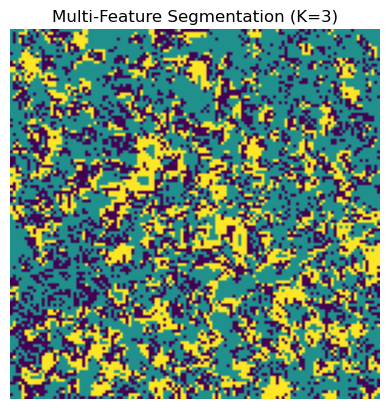

In [39]:
features = np.stack([
    intensity.flatten(),
    gradient.flatten(),
    variance.flatten()
], axis=1)

scaler = StandardScaler()
features_scaled = scaler.fit_transform(features)

kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)

labels = kmeans.fit_predict(features_scaled)

segmented = labels.reshape(image.shape)

plt.imshow(segmented, cmap='viridis')
plt.title("Multi-Feature Segmentation (K=3)")
plt.axis('off')
plt.show()

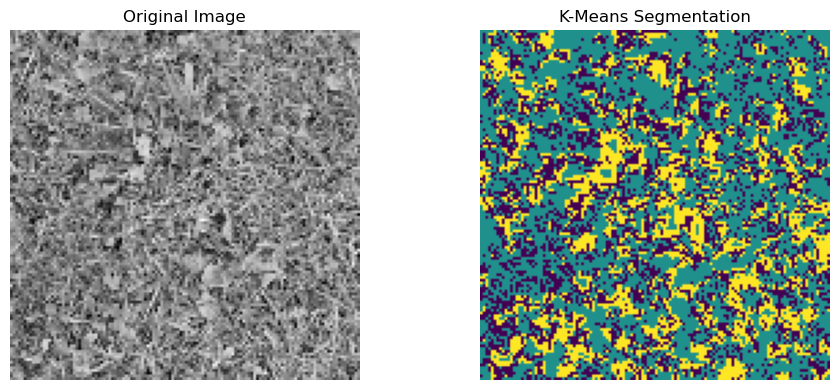

In [40]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(image, cmap='gray')
plt.title("Original Image")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(segmented, cmap='viridis')
plt.title("K-Means Segmentation")
plt.axis('off')

plt.tight_layout()
plt.show()

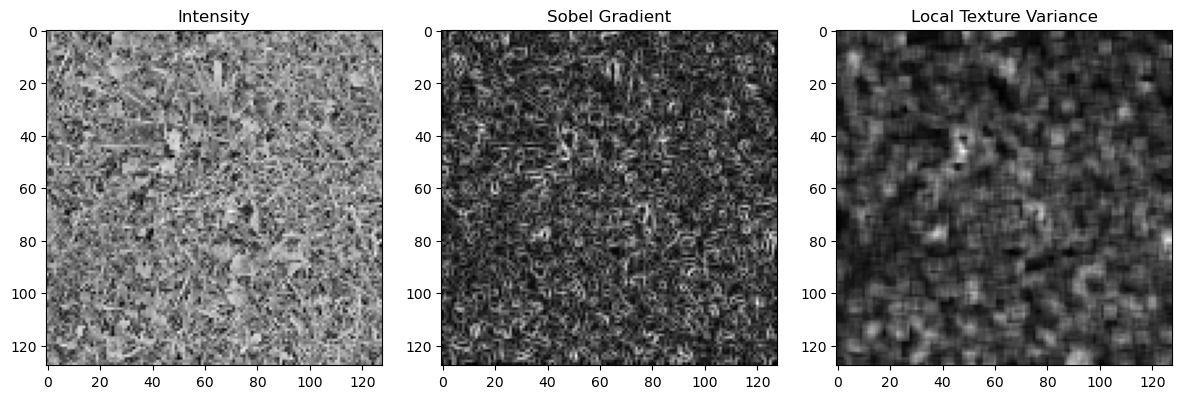

In [41]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(intensity, cmap='gray')
plt.title("Intensity")

plt.subplot(1, 3, 2)
plt.imshow(gradient, cmap='gray')
plt.title("Sobel Gradient")

plt.subplot(1, 3, 3)
plt.imshow(variance, cmap='gray')
plt.title("Local Texture Variance")

plt.tight_layout()
plt.show()

In [ ]:
##Step 6 – Observation
##Observation:
##1. Intensity helps identify differences in pixel brightness.
##2. Gradient magnitude detects boundaries and changes in image intensity.
##3. Local texture variance identifies smooth and rough regions.
##4. K-Means divides the image into three clusters based on combined features.
##5. Some regions may be misclassified because healthy and diseased areas can have similar intensity or texture.